Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Image dimensions: (28, 28)


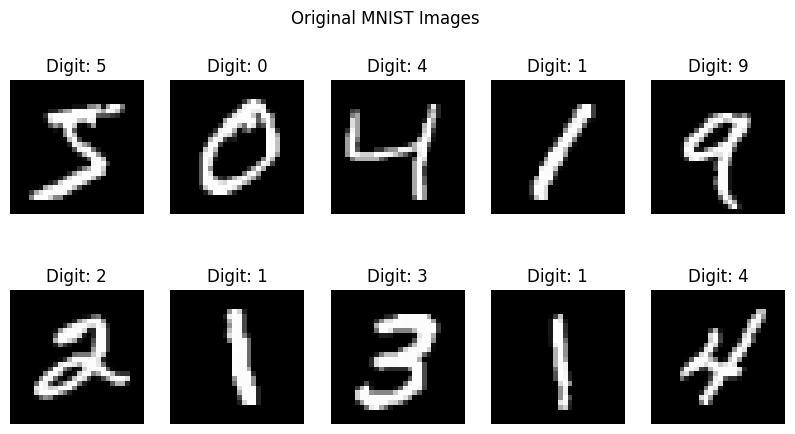


After Normalization:
Training data shape: (60000, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0

Total training samples: 60000
Batch size: 128

PART A COMPLETED SUCCESSFULLY


In [9]:
# ============================================
# PART A: DATASET PREPARATION
# Name: Mithunjai.E
# Roll Number: 24BAD071
# Experiment: Generative Adversarial Network
# ============================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset information
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Image dimensions:", x_train.shape[1:])

# Display sample images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: {}".format(y_train[i]))
    plt.axis('off')

plt.suptitle("Original MNIST Images")
plt.show()

# Normalize pixel values between -1 and 1
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images
x_train = x_train.reshape(-1, 28, 28, 1)

# Display normalized information
print("\nAfter Normalization:")
print("Training data shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# Prepare dataset batches
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)

train_dataset = train_dataset.shuffle(60000).batch(BATCH_SIZE)

print("\nTotal training samples:", len(x_train))
print("Batch size:", BATCH_SIZE)

print("\nPART A COMPLETED SUCCESSFULLY")

In [10]:
# ============================================
# PART B: GENERATOR AND DISCRIMINATOR
# Name: Mithunjai.E
# Roll Number: 24BAD071
# ============================================

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU
from tensorflow.keras.layers import Reshape, Flatten, Input

# Define noise dimension
NOISE_DIM = 100

# ============================================
# GENERATOR MODEL
# ============================================

generator = Sequential([
    Input(shape=(NOISE_DIM,)),

    Dense(256),
    LeakyReLU(negative_slope=0.2),

    Dense(512),
    LeakyReLU(negative_slope=0.2),

    Dense(1024),
    LeakyReLU(negative_slope=0.2),

    Dense(784, activation='tanh'),

    Reshape((28, 28, 1))
], name="Generator")

# Display Generator summary
print("GENERATOR MODEL SUMMARY")
generator.summary()

# ============================================
# DISCRIMINATOR MODEL
# ============================================

discriminator = Sequential([
    Input(shape=(28, 28, 1)),

    Flatten(),

    Dense(512),
    LeakyReLU(negative_slope=0.2),

    Dense(256),
    LeakyReLU(negative_slope=0.2),

    Dense(1, activation='sigmoid')
], name="Discriminator")

# Display Discriminator summary
print("\nDISCRIMINATOR MODEL SUMMARY")
discriminator.summary()

# ============================================
# COMPILE DISCRIMINATOR
# ============================================

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ============================================
# COMBINE GENERATOR AND DISCRIMINATOR
# ============================================

discriminator.trainable = False

gan_input = Input(shape=(NOISE_DIM,))

generated_image = generator(gan_input)

gan_output = discriminator(generated_image)

gan = tf.keras.Model(
    gan_input,
    gan_output,
    name="GAN"
)

gan.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss='binary_crossentropy'
)

# Display GAN summary
print("\nCOMPLETE GAN MODEL SUMMARY")
gan.summary()

print("\nPART B COMPLETED SUCCESSFULLY")

GENERATOR MODEL SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,486,352 (5.67 MB)

 Trainable params: 1,486,352 (5.67 MB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 2,019,857 (7.71 MB)

 Trainable params: 1,486,352 (5.67 MB)

 Non-trainable params: 533,505 (2.04 MB)


PART B COMPLETED SUCCESSFULLY


Epoch 1/50 | D Loss: 0.1675 | G Loss: 3.4294
Epoch 2/50 | D Loss: 0.0648 | G Loss: 5.1042
Epoch 3/50 | D Loss: 0.0737 | G Loss: 5.8088
Epoch 4/50 | D Loss: 0.0772 | G Loss: 5.4905
Epoch 5/50 | D Loss: 0.0753 | G Loss: 5.3890
Epoch 6/50 | D Loss: 0.0792 | G Loss: 5.3382
Epoch 7/50 | D Loss: 0.0852 | G Loss: 5.3055
Epoch 8/50 | D Loss: 0.0917 | G Loss: 5.2159
Epoch 9/50 | D Loss: 0.0982 | G Loss: 5.1510
Epoch 10/50 | D Loss: 0.1060 | G Loss: 5.0500


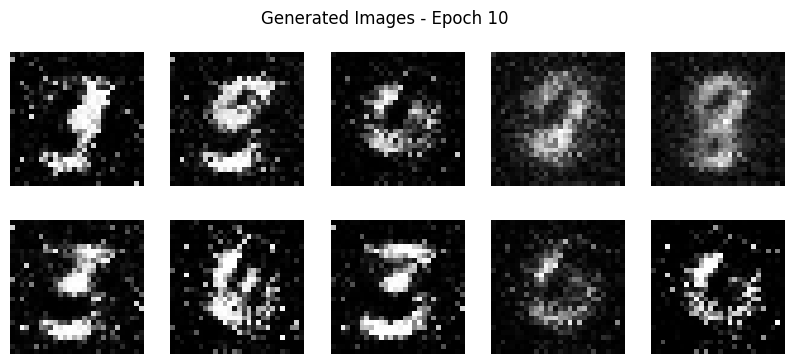

Epoch 11/50 | D Loss: 0.1139 | G Loss: 4.9642
Epoch 12/50 | D Loss: 0.1212 | G Loss: 4.8750
Epoch 13/50 | D Loss: 0.1273 | G Loss: 4.7984
Epoch 14/50 | D Loss: 0.1343 | G Loss: 4.7305
Epoch 15/50 | D Loss: 0.1436 | G Loss: 4.6582
Epoch 16/50 | D Loss: 0.1527 | G Loss: 4.5678
Epoch 17/50 | D Loss: 0.1608 | G Loss: 4.4802
Epoch 18/50 | D Loss: 0.1689 | G Loss: 4.3974
Epoch 19/50 | D Loss: 0.1770 | G Loss: 4.3138
Epoch 20/50 | D Loss: 0.1863 | G Loss: 4.2292


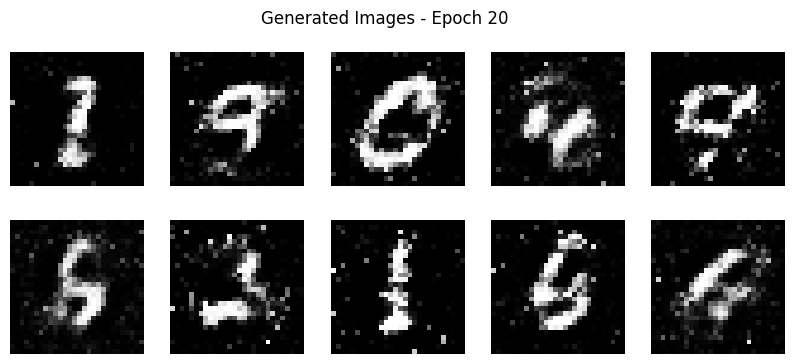

Epoch 21/50 | D Loss: 0.1951 | G Loss: 4.1413
Epoch 22/50 | D Loss: 0.2029 | G Loss: 4.0628
Epoch 23/50 | D Loss: 0.2102 | G Loss: 3.9909
Epoch 24/50 | D Loss: 0.2177 | G Loss: 3.9227
Epoch 25/50 | D Loss: 0.2250 | G Loss: 3.8549
Epoch 26/50 | D Loss: 0.2322 | G Loss: 3.7894
Epoch 27/50 | D Loss: 0.2393 | G Loss: 3.7267
Epoch 28/50 | D Loss: 0.2462 | G Loss: 3.6654
Epoch 29/50 | D Loss: 0.2532 | G Loss: 3.6052
Epoch 30/50 | D Loss: 0.2602 | G Loss: 3.5465


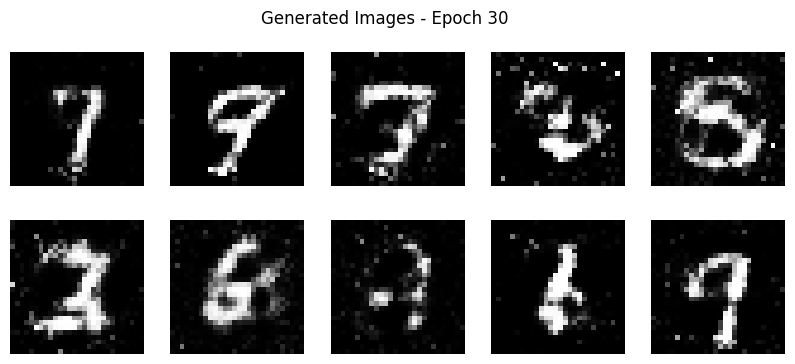

Epoch 31/50 | D Loss: 0.2675 | G Loss: 3.4891
Epoch 32/50 | D Loss: 0.2746 | G Loss: 3.4334
Epoch 33/50 | D Loss: 0.2818 | G Loss: 3.3786
Epoch 34/50 | D Loss: 0.2890 | G Loss: 3.3250
Epoch 35/50 | D Loss: 0.2961 | G Loss: 3.2725
Epoch 36/50 | D Loss: 0.3032 | G Loss: 3.2213
Epoch 37/50 | D Loss: 0.3102 | G Loss: 3.1708
Epoch 38/50 | D Loss: 0.3169 | G Loss: 3.1222
Epoch 39/50 | D Loss: 0.3233 | G Loss: 3.0760
Epoch 40/50 | D Loss: 0.3297 | G Loss: 3.0310


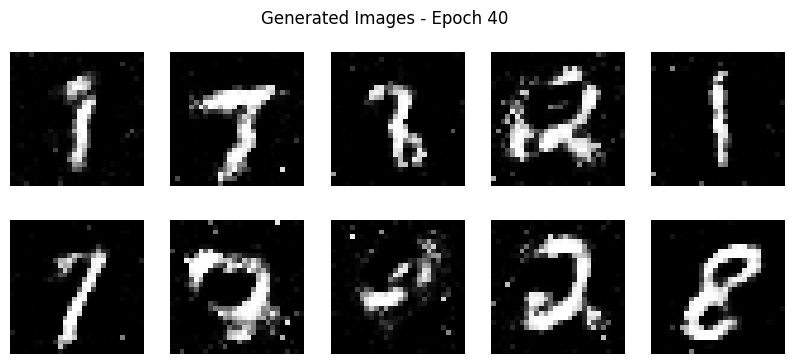

Epoch 41/50 | D Loss: 0.3358 | G Loss: 2.9879
Epoch 42/50 | D Loss: 0.3417 | G Loss: 2.9464
Epoch 43/50 | D Loss: 0.3474 | G Loss: 2.9062
Epoch 44/50 | D Loss: 0.3529 | G Loss: 2.8677
Epoch 45/50 | D Loss: 0.3582 | G Loss: 2.8307
Epoch 46/50 | D Loss: 0.3633 | G Loss: 2.7949
Epoch 47/50 | D Loss: 0.3683 | G Loss: 2.7605
Epoch 48/50 | D Loss: 0.3731 | G Loss: 2.7270
Epoch 49/50 | D Loss: 0.3777 | G Loss: 2.6950
Epoch 50/50 | D Loss: 0.3822 | G Loss: 2.6641


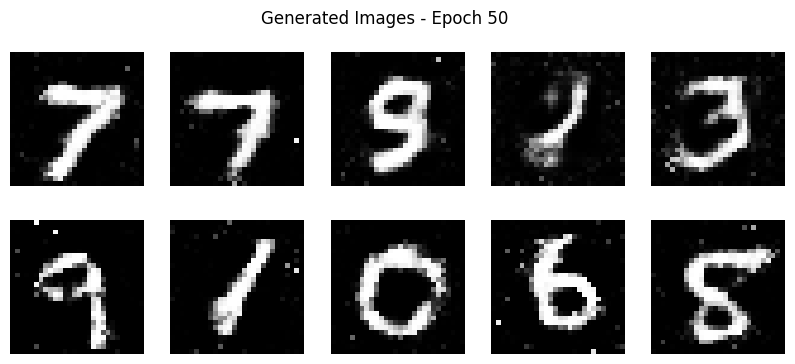

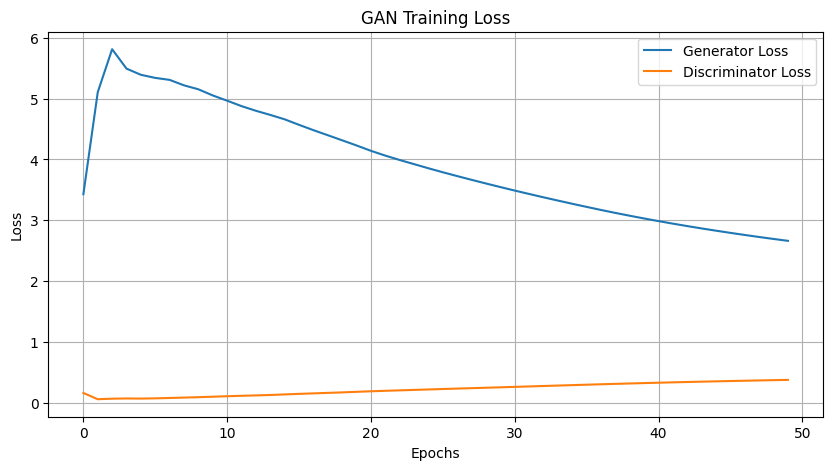


PART C COMPLETED SUCCESSFULLY


In [7]:
# ============================================
# PART C: GAN TRAINING AND EVALUATION
# Name: Mithunjai.E
# Roll Number: 24BAD071
# ============================================

# Define training parameters
EPOCHS = 50
BATCH_SIZE = 128
NOISE_DIM = 100

# Store losses
generator_losses = []
discriminator_losses = []

# Function to display generated images
def display_generated_images(epoch):

    noise = tf.random.normal([10, NOISE_DIM])

    generated_images = generator.predict(
        noise,
        verbose=0
    )

    generated_images = (generated_images + 1) / 2

    plt.figure(figsize=(10, 4))

    for i in range(10):
        plt.subplot(2, 5, i + 1)

        plt.imshow(
            generated_images[i, :, :, 0],
            cmap='gray'
        )

        plt.axis('off')

    plt.suptitle("Generated Images - Epoch {}".format(epoch))
    plt.show()


# ============================================
# GAN TRAINING LOOP
# ============================================

for epoch in range(EPOCHS):

    g_loss_list = []
    d_loss_list = []

    for real_images in train_dataset:

        batch_size = tf.shape(real_images)[0]

        # Create random noise
        noise = tf.random.normal(
            [batch_size, NOISE_DIM]
        )

        # Generate fake images
        fake_images = generator(noise, training=True)

        # Labels for real and fake images
        real_labels = tf.ones((batch_size, 1))
        fake_labels = tf.zeros((batch_size, 1))

        # Train Discriminator
        discriminator.trainable = True

        d_loss_real = discriminator.train_on_batch(
            real_images,
            real_labels
        )

        d_loss_fake = discriminator.train_on_batch(
            fake_images,
            fake_labels
        )

        d_loss = 0.5 * (
            np.array(d_loss_real) +
            np.array(d_loss_fake)
        )

        # Train Generator through combined GAN
        discriminator.trainable = False

        noise = tf.random.normal(
            [batch_size, NOISE_DIM]
        )

        misleading_labels = tf.ones((batch_size, 1))

        g_loss = gan.train_on_batch(
            noise,
            misleading_labels
        )

        d_loss_list.append(float(d_loss[0]))
        g_loss_list.append(float(g_loss))

    # Store average losses
    avg_d_loss = np.mean(d_loss_list)
    avg_g_loss = np.mean(g_loss_list)

    discriminator_losses.append(avg_d_loss)
    generator_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f}"
    )

    # Display images every 10 epochs
    if (epoch + 1) % 10 == 0:
        display_generated_images(epoch + 1)


# ============================================
# PLOT GENERATOR AND DISCRIMINATOR LOSSES
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    generator_losses,
    label='Generator Loss'
)

plt.plot(
    discriminator_losses,
    label='Discriminator Loss'
)

plt.title("GAN Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

print("\nPART C COMPLETED SUCCESSFULLY")

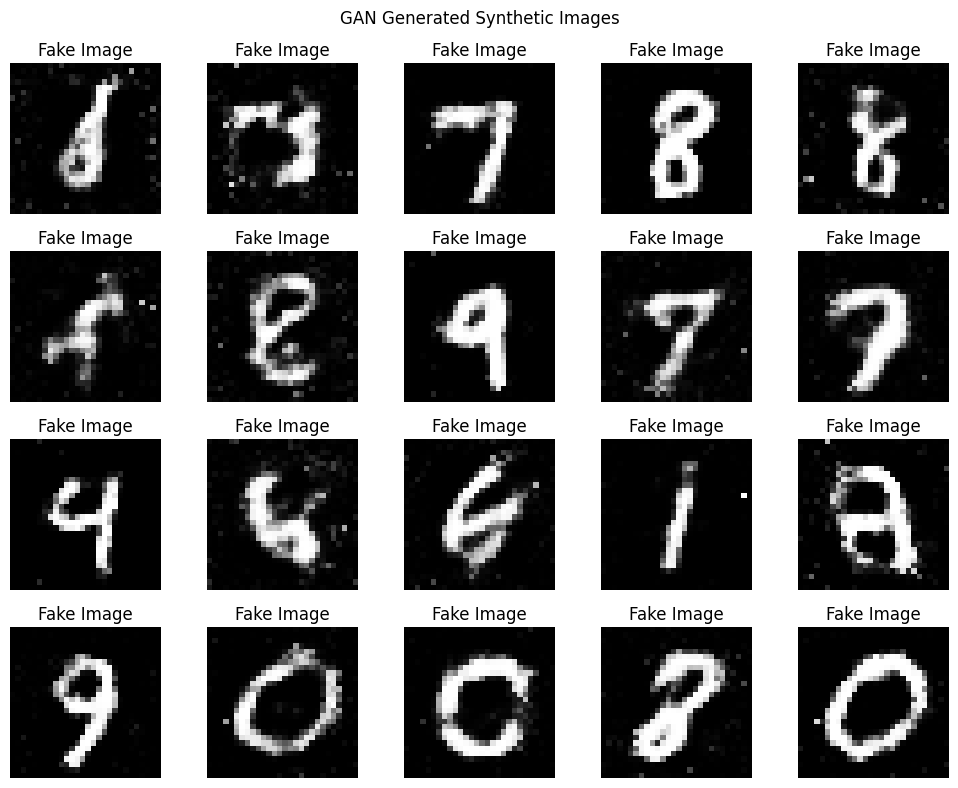

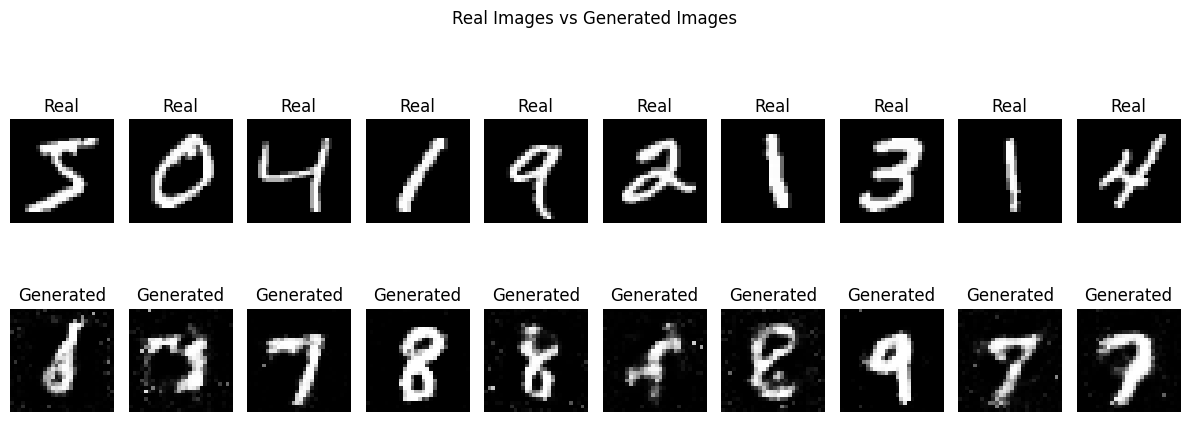

Original Image Shape: (28, 28, 1)
Generated Image Shape: (28, 28, 1)
Total Generated Images: 20
Generated Image Diversity Score: 0.16781095

GAN TRAINING RESULTS
    Epoch  Generator Loss  Discriminator Loss
45     46        2.794920            0.363343
46     47        2.760509            0.368261
47     48        2.727020            0.373101
48     49        2.694992            0.377703
49     50        2.664067            0.382151

Saved Files:
1. gan_generator.keras
2. gan_discriminator.keras
3. generated_images.npy
4. gan_training_results.csv

PART D COMPLETED SUCCESSFULLY


In [8]:
# ============================================
# PART D: IMAGE GENERATION AND VISUALIZATION
# Name: Mithunjai.E
# Roll Number: 24BAD071
# ============================================

# ============================================
# GENERATE SYNTHETIC IMAGES
# ============================================

# Generate 20 random noise vectors
noise = tf.random.normal([20, NOISE_DIM])

# Generate synthetic images
generated_images = generator.predict(
    noise,
    verbose=0
)

# Convert pixel values from -1 to 1 into 0 to 1
generated_images = (generated_images + 1) / 2

# Display generated images
plt.figure(figsize=(10, 8))

for i in range(20):

    plt.subplot(4, 5, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0],
        cmap='gray'
    )

    plt.title("Fake Image")
    plt.axis('off')

plt.suptitle("GAN Generated Synthetic Images")
plt.tight_layout()
plt.show()


# ============================================
# COMPARE REAL AND GENERATED IMAGES
# ============================================

plt.figure(figsize=(12, 5))

for i in range(10):

    # Real image
    plt.subplot(2, 10, i + 1)

    plt.imshow(
        (x_train[i, :, :, 0] + 1) / 2,
        cmap='gray'
    )

    plt.title("Real")
    plt.axis('off')

    # Generated image
    plt.subplot(2, 10, i + 11)

    plt.imshow(
        generated_images[i, :, :, 0],
        cmap='gray'
    )

    plt.title("Generated")
    plt.axis('off')

plt.suptitle("Real Images vs Generated Images")
plt.tight_layout()
plt.show()


# ============================================
# CHECK GENERATED IMAGE DIMENSIONS
# ============================================

print("Original Image Shape:", x_train[0].shape)

print(
    "Generated Image Shape:",
    generated_images[0].shape
)

print(
    "Total Generated Images:",
    len(generated_images)
)


# ============================================
# CALCULATE IMAGE DIVERSITY
# ============================================

generated_flat = generated_images.reshape(20, -1)

diversity = np.mean(
    np.std(generated_flat, axis=0)
)

print("Generated Image Diversity Score:", diversity)


# ============================================
# SAVE GENERATED IMAGES
# ============================================

np.save(
    "generated_images.npy",
    generated_images
)

# Save Generator model
generator.save("gan_generator.keras")

# Save Discriminator model
discriminator.save("gan_discriminator.keras")


# ============================================
# SAVE TRAINING LOSSES
# ============================================

results = pd.DataFrame({
    'Epoch': range(1, EPOCHS + 1),
    'Generator Loss': generator_losses,
    'Discriminator Loss': discriminator_losses
})

print("\nGAN TRAINING RESULTS")
print(results.tail())

results.to_csv(
    "gan_training_results.csv",
    index=False
)

print("\nSaved Files:")
print("1. gan_generator.keras")
print("2. gan_discriminator.keras")
print("3. generated_images.npy")
print("4. gan_training_results.csv")

print("\nPART D COMPLETED SUCCESSFULLY")